In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
# Jumlah data mahasiswa
jumlah_mahasiswa = 500

# Membuat fitur akademik simulasi
ipk = np.round(
    np.random.uniform(1.80, 4.00, jumlah_mahasiswa), 2
)

kehadiran = np.random.randint(
    50, 101, jumlah_mahasiswa
)

mata_kuliah_lulus = np.random.randint(
    12, 49, jumlah_mahasiswa
)

# Membuat skor simulasi untuk menentukan status kelulusan
skor = (
    0.40 * ((ipk - 1.80) / (4.00 - 1.80))
    + 0.25 * ((kehadiran - 50) / 50)
    + 0.35 * ((mata_kuliah_lulus - 12) / 36)
)

# Tambahkan sedikit variasi acak
skor = skor + np.random.normal(
    0, 0.10, jumlah_mahasiswa
)

# Label simulasi
status = np.where(
    skor >= 0.55,
    "Lulus Tepat Waktu",
    "Tidak Tepat Waktu"
)

# Membuat DataFrame
data = pd.DataFrame({
    "IPK": ipk,
    "Kehadiran": kehadiran,
    "Mata_Kuliah_Lulus": mata_kuliah_lulus,
    "Status_Kelulusan": status
})

print("Dataset berhasil dibuat.")
print("Jumlah mahasiswa:", len(data))

display(data.head(10))

Dataset berhasil dibuat.
Jumlah mahasiswa: 500


,IPK,Kehadiran,Mata_Kuliah_Lulus,Status_Kelulusan
0,2.62,66,22,Tidak Tepat Waktu
1,3.89,58,34,Lulus Tepat Waktu
2,3.41,82,12,Tidak Tepat Waktu
3,3.12,69,48,Lulus Tepat Waktu
4,2.14,62,32,Tidak Tepat Waktu
5,2.14,77,37,Tidak Tepat Waktu
6,1.93,97,47,Lulus Tepat Waktu
7,3.71,78,34,Lulus Tepat Waktu
8,3.12,62,12,Tidak Tepat Waktu
9,3.36,95,26,Lulus Tepat Waktu


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   IPK                500 non-null    float64
 1   Kehadiran          500 non-null    int64  
 2   Mata_Kuliah_Lulus  500 non-null    int64  
 3   Status_Kelulusan   500 non-null    object 
dtypes: float64(1), int64(2), object(1)
memory usage: 15.8+ KB

Jumlah nilai kosong:


,0
IPK,0
Kehadiran,0
Mata_Kuliah_Lulus,0
Status_Kelulusan,0



Statistik deskriptif:


,IPK,Kehadiran,Mata_Kuliah_Lulus
count,500.000000,500.000000,500.000000
mean,2.896720,74.946000,30.882000
std,0.657175,15.164796,10.690962
min,1.810000,50.000000,12.000000
25%,2.330000,61.000000,22.000000
50%,2.930000,75.000000,31.000000
75%,3.462500,87.250000,40.000000
max,3.980000,100.000000,48.000000



Distribusi status kelulusan:


,count
Status_Kelulusan,
Tidak Tepat Waktu,281
Lulus Tepat Waktu,219


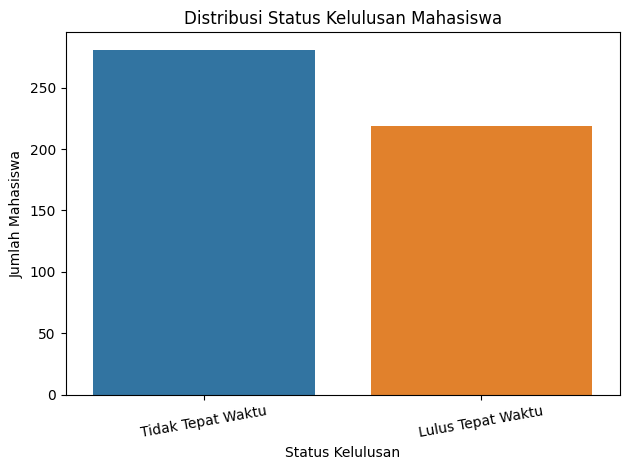

In [3]:
print("Informasi dataset:")
data.info()

print("\nJumlah nilai kosong:")
display(data.isnull().sum())

print("\nStatistik deskriptif:")
display(data.describe())

print("\nDistribusi status kelulusan:")
display(data["Status_Kelulusan"].value_counts())

# Visualisasi distribusi status
sns.countplot(
    data=data,
    x="Status_Kelulusan",
    hue="Status_Kelulusan",
    legend=False
)

plt.title("Distribusi Status Kelulusan Mahasiswa")
plt.xlabel("Status Kelulusan")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [4]:
X = data[
    ["IPK", "Kehadiran", "Mata_Kuliah_Lulus"]
]

y = data["Status_Kelulusan"]

print("Fitur yang digunakan:")
print(X.columns.tolist())

print("\nKategori target:")
print(y.unique())

Fitur yang digunakan:
['IPK', 'Kehadiran', 'Mata_Kuliah_Lulus']

Kategori target:
['Tidak Tepat Waktu' 'Lulus Tepat Waktu']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 400
Jumlah data testing: 100


In [6]:
model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        DecisionTreeClassifier(
            criterion="gini",
            max_depth=4,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        )
    )
])

# Melatih model
model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")

Model Decision Tree berhasil dilatih.


In [7]:
# Prediksi pada data testing
y_pred = model.predict(X_test)

# Menghitung metrik
akurasi = accuracy_score(y_test, y_pred)
presisi = precision_score(
    y_test, y_pred,
    pos_label="Lulus Tepat Waktu",
    zero_division=0
)
recall = recall_score(
    y_test, y_pred,
    pos_label="Lulus Tepat Waktu",
    zero_division=0
)
f1 = f1_score(
    y_test, y_pred,
    pos_label="Lulus Tepat Waktu",
    zero_division=0
)

print("HASIL EVALUASI MODEL")
print("=" * 35)
print(f"Accuracy  : {akurasi:.2%}")
print(f"Precision : {presisi:.2%}")
print(f"Recall    : {recall:.2%}")
print(f"F1-score  : {f1:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

HASIL EVALUASI MODEL
Accuracy  : 83.00%
Precision : 80.00%
Recall    : 81.82%
F1-score  : 80.90%

Classification Report:
                   precision    recall  f1-score   support

Lulus Tepat Waktu       0.80      0.82      0.81        44
Tidak Tepat Waktu       0.85      0.84      0.85        56

         accuracy                           0.83       100
        macro avg       0.83      0.83      0.83       100
     weighted avg       0.83      0.83      0.83       100



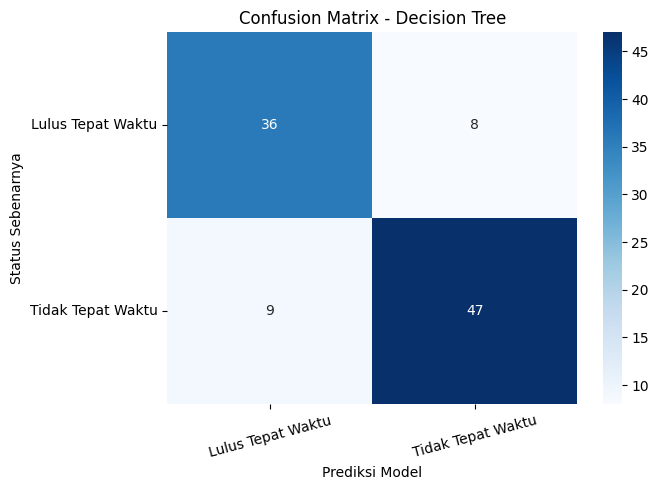

In [8]:
label_kelas = [
    "Lulus Tepat Waktu",
    "Tidak Tepat Waktu"
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=label_kelas
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_kelas,
    yticklabels=label_kelas
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Prediksi Model")
plt.ylabel("Status Sebenarnya")
plt.xticks(rotation=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

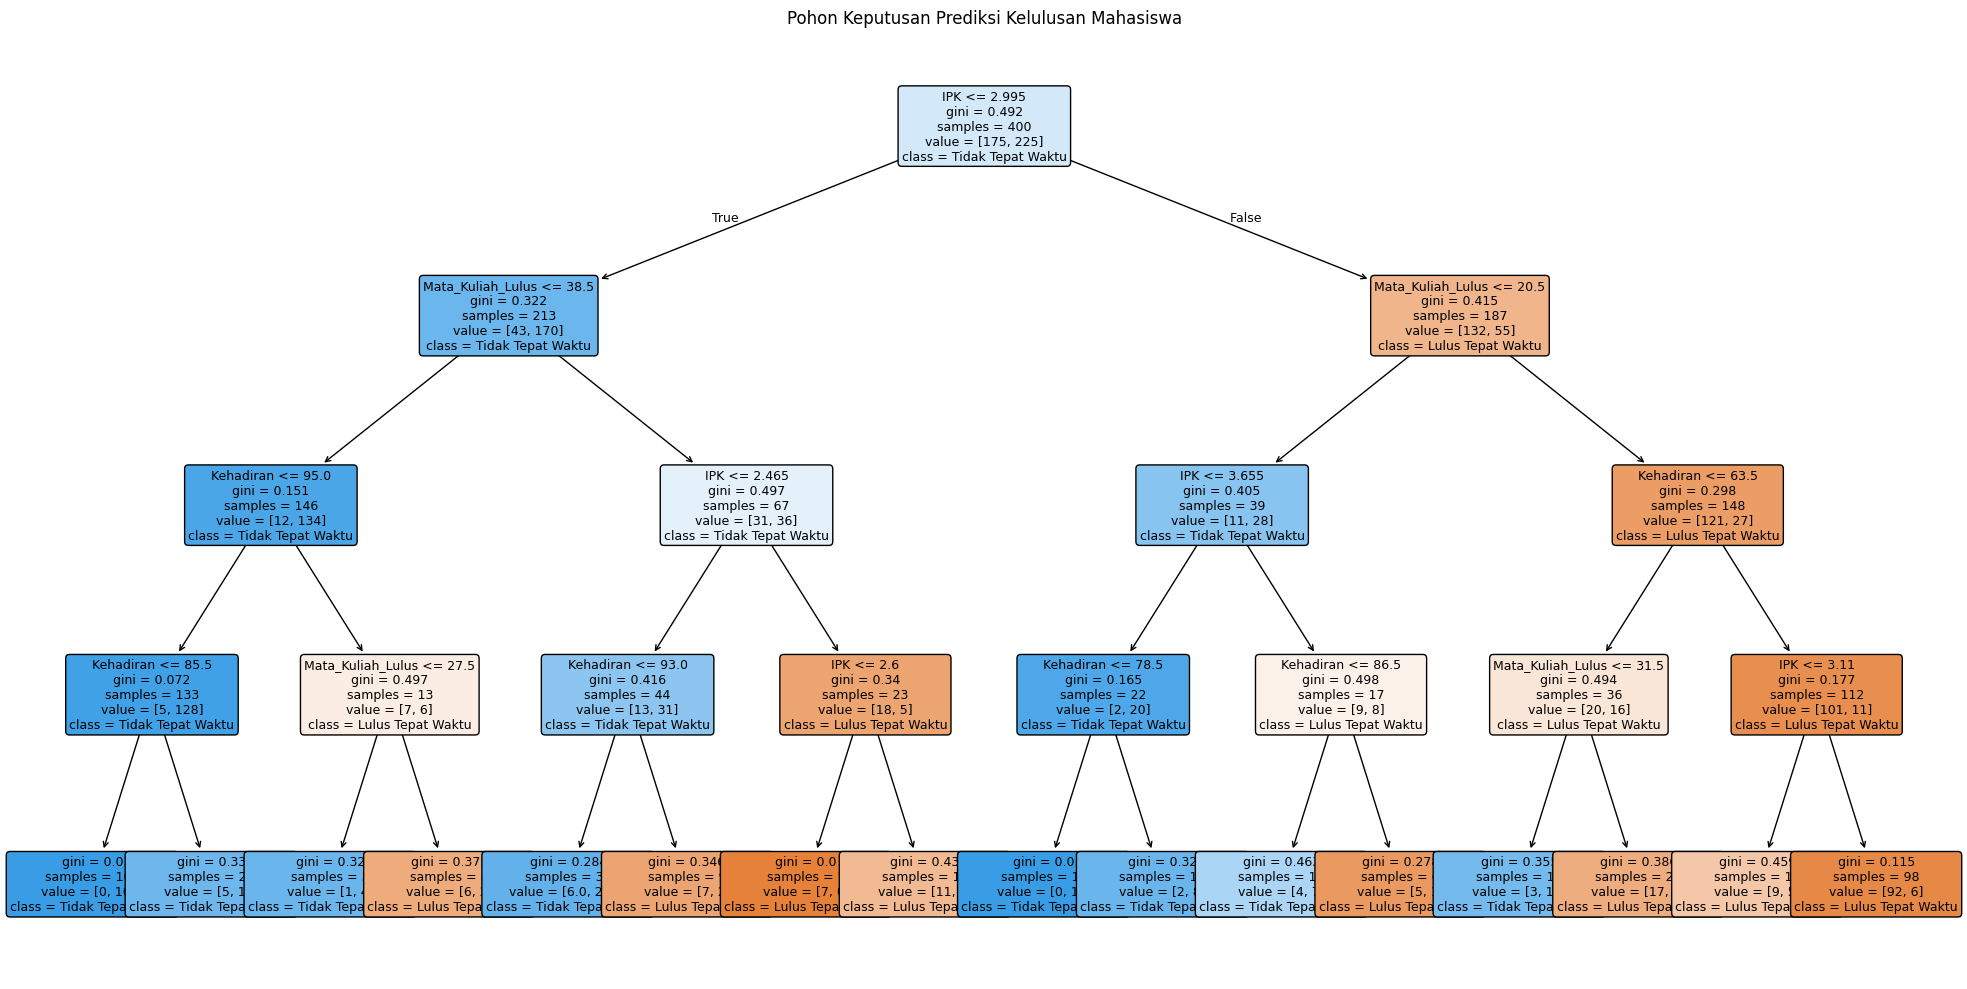

In [9]:
pohon = model.named_steps["classifier"]

plt.figure(figsize=(20, 10))

plot_tree(
    pohon,
    feature_names=X.columns.tolist(),
    class_names=pohon.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Pohon Keputusan Prediksi Kelulusan Mahasiswa")
plt.tight_layout()
plt.show()

,Fitur,Importance
0,IPK,0.523
2,Mata_Kuliah_Lulus,0.301
1,Kehadiran,0.175


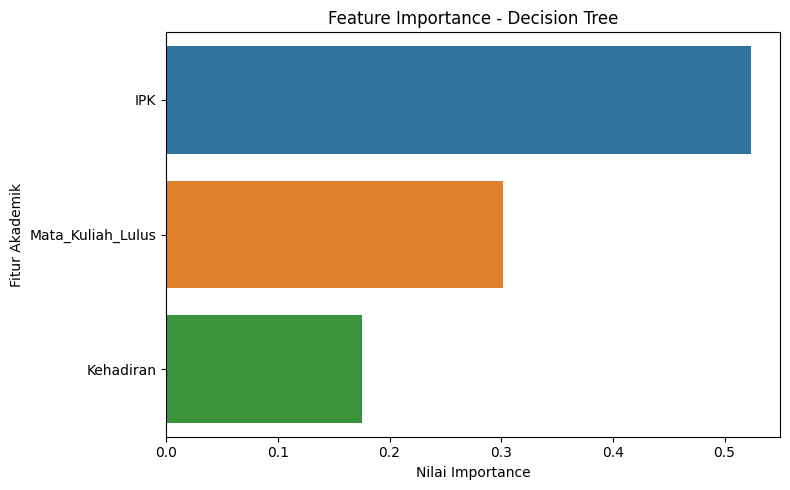

In [10]:
importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": pohon.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance.round(3))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Fitur",
    hue="Fitur",
    legend=False
)

plt.title("Feature Importance - Decision Tree")
plt.xlabel("Nilai Importance")
plt.ylabel("Fitur Akademik")
plt.tight_layout()
plt.show()

In [11]:
# Contoh data mahasiswa baru
mahasiswa_baru = pd.DataFrame([{
    "IPK": 3.50,
    "Kehadiran": 90,
    "Mata_Kuliah_Lulus": 38
}])

# Melakukan prediksi
hasil_prediksi = model.predict(mahasiswa_baru)[0]

print("DATA MAHASISWA BARU")
display(mahasiswa_baru)

print("HASIL PREDIKSI")
print("Status:", hasil_prediksi)

# Probabilitas prediksi
probabilitas = model.predict_proba(mahasiswa_baru)[0]
kelas = model.named_steps["classifier"].classes_

print("\nProbabilitas setiap kelas:")
for nama_kelas, nilai in zip(kelas, probabilitas):
    print(f"{nama_kelas}: {nilai:.2%}")

DATA MAHASISWA BARU


,IPK,Kehadiran,Mata_Kuliah_Lulus
0,3.5,90,38


HASIL PREDIKSI
Status: Lulus Tepat Waktu

Probabilitas setiap kelas:
Lulus Tepat Waktu: 93.88%
Tidak Tepat Waktu: 6.12%


In [13]:
print("KESIMPULAN IMPLEMENTASI")
print("=" * 40)

print(
    f"Model Decision Tree memperoleh accuracy sebesar {akurasi:.2%}, "
    f"precision {presisi:.2%}, recall {recall:.2%}, "
    f"dan F1-score {f1:.2%} pada data testing."
)

print(
    "\nImplementasi ini menunjukkan tahapan Supervised Learning, "
    "mulai dari persiapan data, pelatihan model, prediksi, "
    "hingga evaluasi."
)

print(
    "\nHasil masih bersifat pembelajaran karena menggunakan "
    "data simulasi dan belum dapat digunakan untuk keputusan "
    "akademik nyata."
)

KESIMPULAN IMPLEMENTASI
Model Decision Tree memperoleh accuracy sebesar 83.00%, precision 80.00%, recall 81.82%, dan F1-score 80.90% pada data testing.

Implementasi ini menunjukkan tahapan Supervised Learning, mulai dari persiapan data, pelatihan model, prediksi, hingga evaluasi.

Hasil masih bersifat pembelajaran karena menggunakan data simulasi dan belum dapat digunakan untuk keputusan akademik nyata.
